# Partie 2 : Big Data : maladies des feuilles de pomme de terre avec Hadoop et Spark
## Dataset Kaggle *setimage* (aymenhadjslimane)

**Objectif.** Classer des photos de feuilles de pomme de terre en **6 classes** : `bacterie`, `champignons`,
`mildiou`, `pest`, `saine` et `virus`.

**Consigne.** Sur ce dataset « Big Data », utiliser **Hadoop / Spark** et reprendre la chaîne à partir de la
**Transformation** : Transformation → ML → Évaluation → Déploiement. Les étapes Data et Prétraitement sont
traitées plus brièvement, mais elles sont indispensables : elles révèlent un problème majeur du dataset
(section 3).

**Pourquoi ce dataset relève du Big Data.** Les images sont des photos de haute résolution (de 1 500 à
2 000 pixels de côté, environ 0,5 à 1 Mo chacune). Une image de 1 932 × 1 932 pixels représente 11 millions
de valeurs (3 couleurs). Le volume brut à traiter dépasse rapidement la mémoire d'une machine, et le
traitement image par image est **indépendant** d'une image à l'autre.

**Architecture utilisée.**

| Rôle | Outil | Ce qu'il fait ici |
|---|---|---|
| Stockage distribué | **Hadoop HDFS**  | stocke les images en blocs répliqués sur les DataNodes |
| Calcul distribué | **Apache Spark** (PySpark, mode local `local[4]`) | inventaire des fichiers, détection des doublons, extraction des caractéristiques de chaque image en parallèle |
| Apprentissage distribué | **Spark MLlib** | normalisation, modèles de classification, validation croisée, évaluation |

**Pas de deep learning.**On calcule à la place des
**caractéristiques visuelles interprétables** (couleurs, taches brunes ou jaunes, texture), en parallèle avec
Spark. 

## Data

## 1. Données et démarrage de Spark

### 1.1 Session Spark
Configuration :
- `JAVA_HOME` vers Java 8 (Spark 3.5 exige Java 8, 11 ou 17) ;
- `SPARK_LOCAL_IP`, `spark.driver.host` et `spark.driver.bindAddress` : évitent le blocage au démarrage dû aux
  cartes réseau virtuelles de Docker ;
- `local[4]` : 4 tâches en parallèle (4 processus Python au maximum), pour limiter la mémoire utilisée ;
- `spark.driver.memory = 4g` : en mode local, le driver et les executors partagent cette mémoire.

Ces réglages sont sans effet sous Linux et macOS.

In [1]:
import os, sys, re, glob, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if os.name == "nt":                                           # réglages Windows 
    JAVA8 = r"C:\Program Files\Java\jre1.8.0_461"
    if os.path.exists(JAVA8):
        os.environ["JAVA_HOME"] = JAVA8
    os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

from pyspark.sql import SparkSession, functions as F, types as T

spark = (SparkSession.builder
         .master("local[4]")
         .appName("PommesDeTerre")
         .config("spark.driver.host", "localhost")
         .config("spark.driver.bindAddress", "127.0.0.1")
         .config("spark.driver.memory", "4g")
         .config("spark.python.worker.memory", "512m")
         .config("spark.sql.shuffle.partitions", "8")
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
sc = spark.sparkContext
sc.setLogLevel("ERROR")
print("Spark", spark.version, "| parallélisme :", sc.defaultParallelism)

Spark 3.5.9 | parallélisme : 4


### 1.2 Localisation des images
Le ZIP de Kaggle contient deux dossiers, `train` et `test`, chacun avec 6 sous-dossiers (un par classe). 

*

In [3]:
DATA_DIR = None        # mettre ici le chemin du dossier qui contient train/ et test/ si la recherche échoue

if DATA_DIR is None:
    candidats = [os.path.dirname(p) for p in glob.glob("**/train", recursive=True)
                 if os.path.isdir(os.path.join(os.path.dirname(p), "test"))]
    assert candidats, "Dossier contenant train/ et test/ introuvable : renseigner DATA_DIR"
    DATA_DIR = candidats[0]
DATA_DIR = os.path.abspath(DATA_DIR)

EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp")
fichiers = sorted(f for f in glob.glob(os.path.join(DATA_DIR, "*", "*", "*")) if f.lower().endswith(EXTENSIONS))
autres = sorted(f for f in glob.glob(os.path.join(DATA_DIR, "*", "*", "*")) if not f.lower().endswith(EXTENSIONS))

def uri(chemin):
    return "file:///" + os.path.abspath(chemin).replace("\\", "/").lstrip("/")

from urllib.parse import unquote
def chemin_local(chemin_uri):
    # URI renvoyée par Spark ("file:/C:/..." ou "file:/home/...") -> chemin utilisable par Python
    p = unquote(re.sub(r"^file:/+", "", chemin_uri))
    return p if re.match(r"^[A-Za-z]:", p) else "/" + p

print("Dossier des données :", DATA_DIR)
print("Images trouvées :", len(fichiers), "| autres fichiers ignorés :", len(autres), autres[:5])

Dossier des données : c:\Users\Brahimi\Desktop\2026_2027\Fondements\pommes_de_terre
Images trouvées : 4318 | autres fichiers ignorés : 0 []


### 1.3 Inventaire distribué avec Spark (`binaryFile`)
La source `binaryFile` de Spark lit des fichiers binaires et produit un DataFrame avec une ligne par fichier :
`path`, `modificationTime`, `length` (taille en octets) et `content` (le contenu brut). Tant qu'on ne
sélectionne pas `content`, Spark ne lit **pas** le contenu des images.

On extrait de chaque chemin le **split** (`train` ou `test`) et la **classe** (nom du sous-dossier), avec des
fonctions de Spark (`split`, `element_at`).

In [4]:
inventaire = (spark.read.format("binaryFile").load([uri(f) for f in fichiers])
              .select("path", "length")
              .withColumn("morceaux", F.split("path", "/"))
              .withColumn("split", F.element_at("morceaux", -3))
              .withColumn("classe", F.element_at("morceaux", -2))
              .withColumn("fichier", F.element_at("morceaux", -1))
              .drop("morceaux")
              .cache())

print("Nombre d'images :", inventaire.count())
print(f"Volume total : {inventaire.agg(F.sum('length')).first()[0] / 1e6:.1f} Mo")
repartition = (inventaire.groupBy("classe").pivot("split").count().orderBy("classe").toPandas().set_index("classe"))
repartition["total"] = repartition.sum(axis=1)
repartition

Nombre d'images : 4318
Volume total : 2929.4 Mo


,test,train,total
classe,,,
Bacterie,80,640,720
Champignons,80,640,720
Mildiou,80,640,720
Pest,80,640,720
Saine,80,640,720
Virus,79,639,718


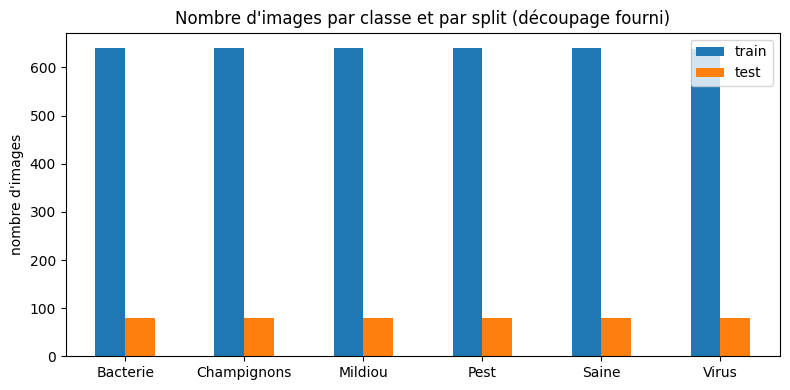

Part de chaque classe (%) : {'Bacterie': 16.7, 'Champignons': 16.7, 'Mildiou': 16.7, 'Pest': 16.7, 'Saine': 16.7, 'Virus': 16.6}
Rapport classe la plus fréquente / la plus rare : 1.0


In [5]:
ax = repartition[["train", "test"]].plot(kind="bar", figsize=(8, 4))
ax.set_title("Nombre d'images par classe et par split (découpage fourni)")
ax.set_xlabel(""); ax.set_ylabel("nombre d'images")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

part = (repartition["total"] / repartition["total"].sum() * 100).round(1)
print("Part de chaque classe (%) :", part.to_dict())
print(f"Rapport classe la plus fréquente / la plus rare : {repartition['total'].max() / repartition['total'].min():.1f}")

**Lecture.** Ce graphique montre si les classes sont **équilibrées**. Si le rapport entre la classe la plus
fréquente et la plus rare dépasse environ 1,5, l'accuracy devient trompeuse, et il
faut des métriques par classe et une pondération des classes.

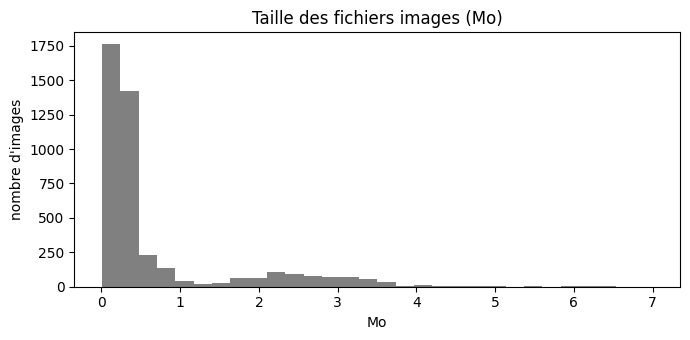

count    4318.00
mean        0.68
std         0.97
min         0.01
25%         0.20
50%         0.26
75%         0.53
max         7.00
Name: Mo, dtype: float64


In [6]:
tailles = inventaire.select((F.col("length") / 1e6).alias("Mo")).toPandas()
ax = tailles["Mo"].plot(kind="hist", bins=30, figsize=(7, 3.5), color="gray")
ax.set_title("Taille des fichiers images (Mo)"); ax.set_xlabel("Mo"); ax.set_ylabel("nombre d'images")
plt.tight_layout(); plt.show()
print(tailles["Mo"].describe().round(2))

### 1.4 Aperçu des images
Une image de chaque classe, tirée du dossier `train`.

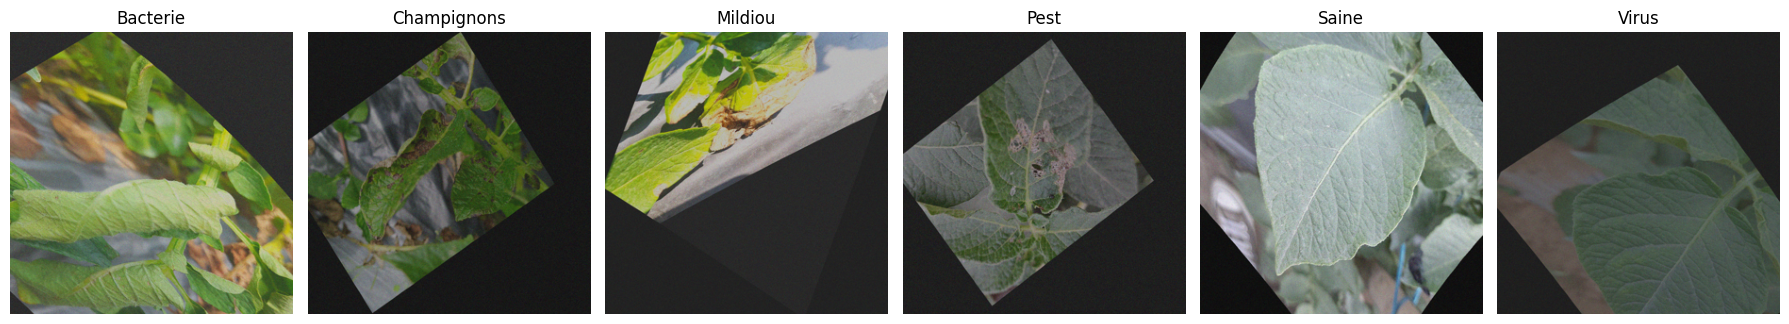

In [7]:
from PIL import Image

exemples = (inventaire.filter(F.col("split") == "train").groupBy("classe")
            .agg(F.first("path").alias("path")).orderBy("classe").toPandas())
fig, axes = plt.subplots(1, len(exemples), figsize=(3 * len(exemples), 3.3))
for ax, (_, ligne) in zip(np.atleast_1d(axes), exemples.iterrows()):
    im = Image.open(chemin_local(ligne["path"])); im.thumbnail((300, 300))
    ax.imshow(im); ax.set_title(ligne["classe"]); ax.axis("off")
plt.tight_layout(); plt.show()

**Lecture.** Les photos sont prises **sur le terrain** : feuilles entières ou plantes, fond de terre ou de
végétation, parfois une main ou un vêtement, des lumières variées. Les maladies se reconnaissent surtout par
la **couleur** (taches brunes, jaunissement, zones claires) et la **texture** (feuilles déformées, trous).


On remarque aussi des images **tournées, avec des bords noirs, du bruit ou des couleurs modifiées** : ce sont
des images **augmentées** artificiellement.

## Stockage HDFS

## 2. Stockage distribué avec Hadoop HDFS

On utilise un cluster Hadoop (image Docker `apache/hadoop:3` : NameNode,
DataNode, ResourceManager, NodeManager). 
Les images sont copiées dans le conteneur du NameNode (`docker cp`), puis dans HDFS (`hdfs dfs -put`).
Si Docker n'est pas démarré, les cellules l'indiquent sans interrompre le notebook.

In [8]:
import subprocess

CONTENEUR = "hadoop-namenode-1"          # nom du conteneur NameNode (vu avec `docker compose ps`)
HDFS_DIR = "/user/hadoop/pommes_de_terre"

def docker(*args):
    r = subprocess.run(["docker", *args], capture_output=True, text=True, encoding="utf-8")
    if r.returncode != 0:
        raise RuntimeError(r.stderr.strip()[-500:])
    return r.stdout

def hdfs(commande, root=False):
    # root=True : commande exécutée en administrateur (nécessaire pour supprimer les fichiers copiés par docker cp)
    return docker("exec", *(["-u", "root"] if root else []), CONTENEUR, "bash", "-c", commande)

try:
    hdfs("hdfs dfs -ls /")
    HDFS_OK = True
    print("Cluster Hadoop accessible.")
except Exception as e:
    HDFS_OK = False
    print("Cluster Hadoop non accessible : section 2 ignorée.\n", e)

Cluster Hadoop non accessible : section 2 ignorée.
 Error response from daemon: container d7b2491d361f1744d2f763e15b37c7c07aade831a746be95a27f53210f82d0ac is not running


In [11]:
if HDFS_OK:
    t0 = time.perf_counter()
    hdfs("rm -rf /tmp/pommes_de_terre", root=True)   # les fichiers copiés par docker cp appartiennent à root
    docker("cp", DATA_DIR, f"{CONTENEUR}:/tmp/pommes_de_terre")
    hdfs(f"hdfs dfs -rm -r -f {HDFS_DIR} && hdfs dfs -mkdir -p {HDFS_DIR} && "
         f"hdfs dfs -put /tmp/pommes_de_terre/* {HDFS_DIR}/")
    print(f"Copie dans HDFS terminée en {time.perf_counter() - t0:.1f} s")
    print(hdfs(f"hdfs dfs -ls {HDFS_DIR}"))
    print("Dossiers / fichiers / octets :")
    print(hdfs(f"hdfs dfs -count {HDFS_DIR}"))
    print(hdfs(f"hdfs dfs -du -h {HDFS_DIR}"))

Copie dans HDFS terminée en 699.3 s
Found 2 items
drwxr-xr-x   - hadoop supergroup          0 2026-11-13 08:22 /user/hadoop/pommes_de_terre/test
drwxr-xr-x   - hadoop supergroup          0 2026-11-13 08:30 /user/hadoop/pommes_de_terre/train

Dossiers / fichiers / octets :
          15         4318         2929385157 /user/hadoop/pommes_de_terre

296.0 M  296.0 M  /user/hadoop/pommes_de_terre/test
2.4 G    2.4 G    /user/hadoop/pommes_de_terre/train



**Lecture.** HDFS contient maintenant **4 318 images** pour un volume de **2,93 Go** (2,4 Go pour `train`,
296 Mo pour `test`). Les 15 dossiers sont le dossier racine, `train`, `test` et les 6 dossiers de classes
de chacun. Le dossier `test` ne représente qu'environ 10 % du volume.

La copie a pris **699 secondes (11,5 minutes)**, soit environ **6 images par seconde** ou **4 Mo/s**. C'est
très lent pour 3 Go, et c'est une illustration concrète du **problème des petits fichiers** : pour chaque
image (0,7 Mo en moyenne), HDFS doit demander un bloc au NameNode, ouvrir un flux vers le DataNode, écrire puis
confirmer. Ce coût fixe par fichier domine largement le temps de transfert des données. Le même volume réparti
dans quelques gros fichiers (Parquet ou SequenceFile) serait copié bien plus vite. Une partie du temps vient
aussi de la copie préalable de Windows vers Docker (`docker cp`).

In [12]:
if HDFS_OK:
    rapport = hdfs(f"hdfs fsck {HDFS_DIR} -files -blocks 2>/dev/null | tail -25")
    lignes_utiles = [l for l in rapport.splitlines() if any(m in l for m in
                     ["Total size", "Total files", "Total blocks", "Average block", "replication", "Status"])]
    print("\n".join(lignes_utiles))

 Default replication factor:	1
 Average block replication:	1.0
 Blocks queued for replication:	0
 Total size:	0 B
 Total files:	0
 Average block group size:	0.0
 Blocks queued for replication:	0


**Lecture du rapport `fsck`.** `hdfs fsck` vérifie l'état des fichiers dans HDFS : nombre de fichiers, nombre
de **blocs**, taille moyenne des blocs, facteur de réplication et statut (`HEALTHY` si aucun bloc n'est perdu).

**Le problème des petits fichiers.** Un bloc HDFS fait 128 Mo, et chaque image (moins de 2 Mo) occupe **un
bloc à elle seule**. On obtient autant de blocs que d'images, avec une taille moyenne de bloc très inférieure
à 128 Mo. Ce n'est pas un problème de place (un bloc n'occupe sur disque que la taille réelle du fichier),
mais le **NameNode garde en mémoire une entrée par fichier et par bloc** (environ 150 octets chacune). Avec
des millions d'images, la mémoire du NameNode devient la limite du cluster, et la lecture d'un grand nombre de
petits fichiers est lente.

**Solutions en production :** regrouper les images dans de gros fichiers, par exemple des **SequenceFiles**
Hadoop, des archives **HAR**, ou des fichiers **Parquet** contenant les octets des images, ou les
caractéristiques déjà extraites.

**Lecture des images depuis HDFS par Spark.** Dans un vrai cluster, Spark lirait directement
`hdfs://namenode:8020/user/hadoop/pommes_de_terre`. Ici, Spark tourne sous Windows et HDFS dans Docker : les
DataNodes s'annoncent avec leur adresse interne au réseau Docker, que Windows ne peut pas joindre. Spark lit
donc la **copie locale** des mêmes fichiers. Le code Spark est identique, seul le chemin change.

## 3. Prétraitement : qualité des données et fuite de données

### 3.1 Images augmentées
Certains noms de fichiers se terminent par `_aug_N` (parfois plusieurs fois : `_aug_6_aug_13`). Ce sont des
**copies modifiées** d'une photo d'origine (rotation, bruit, luminosité, couleurs), créées pour multiplier
artificiellement le nombre d'images. On retrouve la photo d'origine en supprimant ces suffixes : c'est
l'**identifiant de groupe** (`groupe`). Toutes les images d'un même groupe montrent **la même feuille**.

In [9]:
inventaire = inventaire.withColumn("groupe",
    F.regexp_replace(F.regexp_replace("fichier", r"\.[A-Za-z]+$", ""),
                    r"((_aug_\d+)|(\s*-\s*[Cc]opy(\s*\(\d+\))?))+$", ""))
inventaire = inventaire.withColumn("augmentee", F.col("fichier").contains("_aug_").cast("int")).cache()

resume = inventaire.groupBy("split").agg(F.count("*").alias("images"),
                                        F.sum("augmentee").alias("images_augmentees"),
                                        F.countDistinct("groupe").alias("photos_d_origine"))
resume.toPandas()

,split,images,images_augmentees,photos_d_origine
0,test,479,140,464
1,train,3839,1135,2820


Le dataset contient aussi des **copies de fichiers** faites sous Windows (suffixe ` - Copy`, par exemple
`IMG_0294 - Copy.JPG`), parfois elles-mêmes augmentées (`IMG_0293 - Copy_aug_163.jpg`) : ce sont encore des
versions de la même photo. L'identifiant de groupe supprime donc à la fois les suffixes `_aug_N` et ` - Copy`.

In [10]:
taille_groupes = inventaire.groupBy("groupe").count().toPandas()["count"]
print("Nombre d'images par photo d'origine :")
print(taille_groupes.describe().round(1))

Nombre d'images par photo d'origine :
count    3052.0
mean        1.4
std         0.7
min         1.0
25%         1.0
50%         1.0
75%         2.0
max         6.0
Name: count, dtype: float64


**Lecture.** Le nombre de **photos réellement différentes** (groupes) est bien inférieur au nombre d'images :
chaque photo d'origine est déclinée en plusieurs versions augmentées. **Conséquence :** le dataset contient
moins d'information qu'il n'y paraît. Pour savoir si un modèle sait reconnaître une maladie sur une **nouvelle**
feuille, il faut le tester sur des photos qu'il n'a **jamais vues, même modifiées**.

### 3.2 Fuite de données dans le découpage train / test fourni

In [11]:
groupes_train = inventaire.filter(F.col("split") == "train").select("groupe").distinct()
groupes_test = inventaire.filter(F.col("split") == "test").select("groupe").distinct()
communs = groupes_train.join(groupes_test, "groupe")

n_communs, n_test = communs.count(), groupes_test.count()
images_test_fuite = inventaire.filter(F.col("split") == "test").join(communs, "groupe").count()
n_images_test = inventaire.filter(F.col("split") == "test").count()

print(f"Photos d'origine présentes à la fois dans train et dans test : {n_communs} sur {n_test} photos du test")
print(f"Images du test dont une version (originale ou augmentée) est dans le train : "
      f"{images_test_fuite} sur {n_images_test} ({images_test_fuite / max(n_images_test, 1):.0%})")
inventaire.join(communs, "groupe").select("groupe", "split", "classe", "fichier").orderBy("groupe", "split").show(8, truncate=False)

Photos d'origine présentes à la fois dans train et dans test : 232 sur 464 photos du test
Images du test dont une version (originale ou augmentée) est dans le train : 242 sur 479 (51%)
+-------------+-----+-----------+-----------------------+
|groupe       |split|classe     |fichier                |
+-------------+-----+-----------+-----------------------+
|1692332350433|test |Bacterie   |1692332350433.jpg      |
|1692332350433|train|Bacterie   |1692332350433_aug_0.jpg|
|1692332350450|test |Pest       |1692332350450.jpg      |
|1692332350450|train|Pest       |1692332350450_aug_2.jpg|
|1692332350573|test |Pest       |1692332350573_aug_4.jpg|
|1692332350573|train|Pest       |1692332350573.jpg      |
|1692334247043|test |Champignons|1692334247043_aug_7.jpg|
|1692334247043|train|Champignons|1692334247043.jpg      |
+-------------+-----+-----------+-----------------------+
only showing top 8 rows



**Fuite de données massive dans le découpage fourni.**
- **232 des 464 photos d'origine du test (50 %)** ont aussi une version dans l'entraînement.
- **242 des 479 images du test (51 %)** sont donc des versions (originale ou augmentée) de photos que le
  modèle a déjà vues pendant l'entraînement.

Les exemples affichés le montrent : `1692332350433.jpg` est dans le **test** (Bacterie), et sa version augmentée
`1692332350433_aug_0.jpg` dans l'**entraînement**. Inversement, `1692332350573.jpg` est dans l'entraînement
et `1692332350573_aug_4.jpg` dans le test. Les images ont manifestement été **augmentées d'abord, puis
réparties au hasard** entre `train` et `test`, sans tenir compte de la photo d'origine.

**Conséquence :** sur la moitié du test, le modèle n'a pas à reconnaître une maladie sur une feuille nouvelle,
il lui suffit de reconnaître une photo déjà vue, tournée ou recolorée (même feuille, même fond, même lumière).
Le score obtenu avec le découpage fourni serait donc **optimiste** et ne mesurerait pas la capacité réelle du
modèle sur de nouvelles photos.

**Décision :** on n'utilise pas ce découpage pour évaluer le modèle. On construit un découpage **par photo
d'origine**, et on compare les deux pour **mesurer** l'effet de cette fuite.

In [12]:
empreintes = (spark.read.format("binaryFile").load([uri(f) for f in fichiers])
            .select("path", F.sha2("content", 256).alias("sha256")))
doublons = empreintes.groupBy("sha256").agg(F.count("*").alias("n"), F.collect_list("path").alias("fichiers")).filter("n > 1")
print("Groupes de fichiers strictement identiques :", doublons.count())
doublons.select("n", "fichiers").show(5, truncate=120)

Groupes de fichiers strictement identiques : 48
+---+------------------------------------------------------------------------------------------------------------------------+
|  n|                                                                                                                fichiers|
+---+------------------------------------------------------------------------------------------------------------------------+
|  2|[file:/c:/Users/Brahimi/Desktop/2026_2027/Fondements/pommes_de_terre/train/Virus/IMG_20230815_152740(1).jpg, file:/c:...|
|  2|[file:/c:/Users/Brahimi/Desktop/2026_2027/Fondements/pommes_de_terre/train/Mildiou/IMG_9518 (1).JPG, file:/c:/Users/B...|
|  2|[file:/c:/Users/Brahimi/Desktop/2026_2027/Fondements/pommes_de_terre/test/Champignons/IMG_20230815_112512~2 (2).jpg, ...|
|  2|[file:/c:/Users/Brahimi/Desktop/2026_2027/Fondements/pommes_de_terre/train/Pest/IMG_20230816_115049~2.jpg, file:/c:/U...|
|  2|[file:/c:/Users/Brahimi/Desktop/2026_2027/Fondements/pomme

**Lecture.** Un doublon exact présent dans deux classes différentes serait une **erreur d'étiquetage** ; présent
dans `train` et `test`, ce serait une fuite. On doit donc effectuer un découpage par groupe qui place les
doublons de noms identiques du même côté.

## 4. Transformation : extraction distribuée des caractéristiques

### 4.1 Pourquoi transformer les images en caractéristiques
Un modèle classique (régression logistique, forêt aléatoire) ne peut pas apprendre directement sur 11 millions
de pixels : trop de variables, trop peu d'exemples, et aucun lien direct entre un pixel isolé et la maladie.
On transforme donc chaque image en un **vecteur de 31 caractéristiques** qui résument ce qu'un agronome
regarderait :

| Groupe | Variables | Ce qu'elles mesurent |
|---|---|---|
| Couleur moyenne | moyenne et écart-type de R, G, B | teinte générale, homogénéité |
| Teinte (HSV) | histogramme de la teinte en 12 classes, moyenne et écart-type de la saturation et de la luminosité | répartition des couleurs, indépendamment de l'éclairage |
| Symptômes | part de pixels **verts**, **jaunes**, **bruns**, **sombres**, **clairs**, indice d'excès de vert (2G − R − B) | jaunissement (virus, bactéries), nécroses brunes (mildiou, champignons), zones claires |
| Texture | moyenne et écart-type du gradient, variance du laplacien | taches, trous et bords nets, ou au contraire flou |

**Pourquoi l'espace HSV ?** En RVB (rouge, vert, bleu), une même couleur change de valeurs selon la lumière.
En HSV (*Hue* = teinte, *Saturation*, *Value* = luminosité), la teinte est séparée de la luminosité, un brun
reste un brun, au soleil comme à l'ombre.

**Réduction de taille.** Chaque image est d'abord réduite à 256 pixels de côté maximum. JPEG permet de décoder
directement à taille réduite (`Image.draft`), ce qui évite de décompresser 11 millions de valeurs pour rien,
les symptômes recherchés (couleurs, grandes taches) restent visibles.

In [13]:
def caracteristiques(chemin, taille=256):
    # renvoie la liste des 31 caractéristiques d'une image (exécutée sur les workers Spark)
    from PIL import Image
    import numpy as np
    im = Image.open(chemin)
    im.draft("RGB", (taille * 2, taille * 2))          # décodage JPEG à taille réduite
    im = im.convert("RGB")
    im.thumbnail((taille, taille))
    rgb = np.asarray(im, dtype=np.float32) / 255.0
    hsv = np.asarray(im.convert("HSV"), dtype=np.float32) / 255.0
    h, s, v = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    r, g, b = rgb[..., 0], rgb[..., 1], rgb[..., 2]

    f = []
    f += [r.mean(), g.mean(), b.mean(), r.std(), g.std(), b.std()]                     # couleur moyenne
    colore = (s > 0.15) & (v > 0.15)                                                    # pixels vraiment colorés
    hist, _ = np.histogram(h[colore], bins=12, range=(0, 1))
    f += list(hist / max(colore.sum(), 1))                                              # histogramme de teinte
    f += [s.mean(), s.std(), v.mean(), v.std()]
    vert = (h >= 0.17) & (h < 0.45) & colore
    jaune = (h >= 0.11) & (h < 0.17) & colore
    brun = ((h < 0.11) | (h >= 0.92)) & (s > 0.2) & (v > 0.15) & (v < 0.75)
    sombre = v < 0.15
    clair = (v > 0.85) & (s < 0.15)
    f += [vert.mean(), jaune.mean(), brun.mean(), sombre.mean(), clair.mean()]          # symptômes
    f += [(2 * g - r - b).mean()]                                                       # excès de vert
    gris = 0.299 * r + 0.587 * g + 0.114 * b
    gy, gx = np.gradient(gris)
    grad = np.hypot(gx, gy)
    lap = gris[:-2, 1:-1] + gris[2:, 1:-1] + gris[1:-1, :-2] + gris[1:-1, 2:] - 4 * gris[1:-1, 1:-1]
    f += [grad.mean(), grad.std(), lap.var()]                                           # texture
    return [float(x) for x in f]

NOMS = (["r_moy", "g_moy", "b_moy", "r_std", "g_std", "b_std"]
        + [f"teinte_{i:02d}" for i in range(12)]
        + ["s_moy", "s_std", "v_moy", "v_std"]
        + ["part_vert", "part_jaune", "part_brun", "part_sombre", "part_clair", "exces_vert"]
        + ["gradient_moy", "gradient_std", "laplacien_var"])
print(len(NOMS), "caractéristiques")

31 caractéristiques


### 4.2 Calcul distribué avec Spark

**Principe.** On ne fait **pas** circuler les octets des images entre la JVM et Python. Spark distribue la
**liste des chemins** (`sc.parallelize`), découpée en partitions, et chaque tâche ouvre elle-même ses images
et calcule leurs caractéristiques (`mapPartitions`). Ce schéma est celui d'un vrai cluster, où chaque nœud lit
les fichiers les plus proches de lui dans HDFS (**localité des données**).

`mapPartitions` (plutôt que `map`) appelle la fonction **une fois par partition**, les imports et
l'initialisation ne sont faits qu'une fois pour plusieurs dizaines d'images.

**Robustesse :** une image illisible ou corrompue ne doit pas faire échouer tout le calcul. Elle est marquée
avec son message d'erreur, puis écartée et comptée.

In [14]:
lignes = inventaire.select("path", "split", "classe", "groupe").collect()
taches = [(chemin_local(l["path"]), l["split"], l["classe"], l["groupe"]) for l in lignes]
nb_partitions = max(8, len(taches) // 40)           # environ 40 images par tâche

def traiter_partition(lot):
    for chemin, split, classe, groupe in lot:
        try:
            yield (chemin, split, classe, groupe, caracteristiques(chemin), None)
        except Exception as e:
            yield (chemin, split, classe, groupe, None, f"{type(e).__name__}: {e}")

schema = T.StructType([T.StructField("chemin", T.StringType()), T.StructField("split", T.StringType()),
                       T.StructField("classe", T.StringType()), T.StructField("groupe", T.StringType()),
                       T.StructField("features_liste", T.ArrayType(T.DoubleType())),
                       T.StructField("erreur", T.StringType())])

t0 = time.perf_counter()
brut = spark.createDataFrame(sc.parallelize(taches, nb_partitions).mapPartitions(traiter_partition), schema).cache()
n_total = brut.count()
duree = time.perf_counter() - t0
print(f"{n_total} images traitées en {duree:.1f} s ({nb_partitions} partitions, "
      f"{n_total / duree:.1f} images/s) sur {sc.defaultParallelism} cœurs")
erreurs = brut.filter(F.col("erreur").isNotNull())
print("Images illisibles :", erreurs.count())
erreurs.select("chemin", "erreur").show(truncate=False)

4318 images traitées en 111.1 s (107 partitions, 38.9 images/s) sur 4 cœurs
Images illisibles : 0
+------+------+
|chemin|erreur|
+------+------+
+------+------+



**Lecture.** Le temps et le débit (images par seconde) dépendent de la machine. Avec `local[4]`, quatre
partitions sont traitées en même temps, sur un cluster de N machines, le même code traiterait N fois plus de
partitions simultanément, sans modification. C'est l'intérêt de Spark : **le code ne change pas quand le volume
augmente**, seules les ressources changent.

In [20]:
from pyspark.ml.linalg import Vectors, VectorUDT

vers_vecteur = F.udf(lambda l: Vectors.dense(l), VectorUDT())
donnees = (brut.filter(F.col("erreur").isNull())
               .withColumn("features_brutes", vers_vecteur("features_liste"))
               .drop("erreur"))
for i, nom in enumerate(NOMS):                                  # colonnes nommées, pour l'analyse
    donnees = donnees.withColumn(nom, F.col("features_liste")[i])
donnees = donnees.drop("features_liste").coalesce(4).cache()     # 4 partitions = 4 cœurs 
print("Images utilisables :", donnees.count())
donnees.select("classe", "part_vert", "part_jaune", "part_brun", "gradient_moy").show(5)

Images utilisables : 4318
+-------+------------------+------------------+------------------+--------------------+
| classe|         part_vert|        part_jaune|         part_brun|        gradient_moy|
+-------+------------------+------------------+------------------+--------------------+
|  Virus|0.4434661865234375|    0.057373046875|0.0575714111328125|0.043219342827796936|
|  Virus|0.3326568603515625|  0.00433349609375|0.0197601318359375| 0.01033931877464056|
|  Virus|0.7489166259765625|0.0062103271484375|0.0020294189453125|0.013816225342452526|
|  Virus|0.4858245849609375| 0.024932861328125|   0.0826416015625|0.012426435947418213|
|Mildiou|0.1576995849609375|0.0540313720703125|0.0165557861328125|0.020648088306188583|
+-------+------------------+------------------+------------------+--------------------+
only showing top 5 rows



### 4.3 Les caractéristiques distinguent-elles les classes ?
Avant de modéliser, on vérifie que certaines caractéristiques diffèrent selon la classe (moyenne par classe,
calculée par Spark).

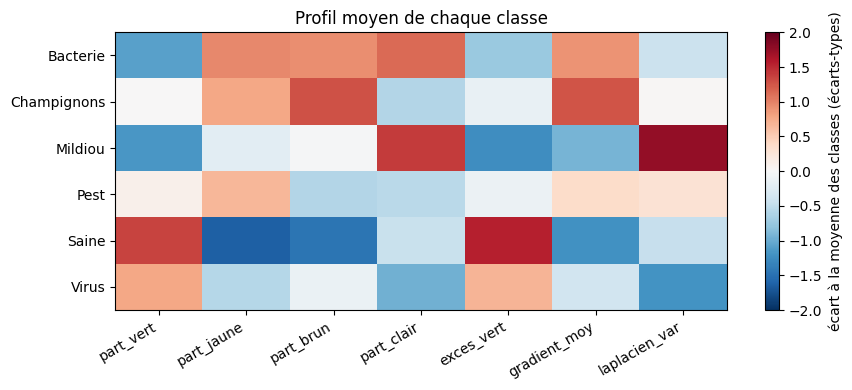

,part_vert,part_jaune,part_brun,part_clair,exces_vert,gradient_moy,laplacien_var
classe,,,,,,,
Bacterie,0.442,0.048,0.074,0.052,0.167,0.040,0.010
Champignons,0.567,0.046,0.081,0.034,0.204,0.040,0.011
Mildiou,0.433,0.033,0.054,0.055,0.136,0.036,0.012
Pest,0.577,0.044,0.042,0.035,0.206,0.039,0.011
Saine,0.719,0.014,0.024,0.036,0.311,0.036,0.010
Virus,0.654,0.028,0.052,0.030,0.256,0.037,0.010


In [21]:
cles = ["part_vert", "part_jaune", "part_brun", "part_clair", "exces_vert", "gradient_moy", "laplacien_var"]
moyennes = donnees.groupBy("classe").agg(*[F.avg(c).alias(c) for c in cles]).orderBy("classe").toPandas().set_index("classe")
normalisees = (moyennes - moyennes.mean()) / moyennes.std()     # écart à la moyenne des classes, en écarts-types
fig, ax = plt.subplots(figsize=(9, 4))
im = ax.imshow(normalisees.values, cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(len(cles))); ax.set_xticklabels(cles, rotation=30, ha="right")
ax.set_yticks(range(len(moyennes))); ax.set_yticklabels(moyennes.index)
plt.colorbar(im, ax=ax, label="écart à la moyenne des classes (écarts-types)")
ax.set_title("Profil moyen de chaque classe")
plt.tight_layout(); plt.show()
moyennes.round(3)

**Lecture de la carte.** Chaque case compare la moyenne d'une caractéristique pour une classe à la moyenne des
six classes : rouge = plus élevée que la moyenne, bleu = plus faible, blanc = dans la moyenne. On s'attend, si
les caractéristiques sont pertinentes, à ce que la classe `saine` ait la plus forte part de vert et la plus
faible part de brun, et que les classes `mildiou` ou `champignons` aient davantage de brun (nécroses). Une
colonne entièrement blanche indique une caractéristique qui ne distingue pas les classes en moyenne (elle
peut néanmoins aider en combinaison avec d'autres).

### 4.4 Deux découpages entraînement / test
- **Découpage A, fourni** : les dossiers `train` et `test` de Kaggle. Il contient la fuite de la section 3.2,
  il est conservé uniquement pour **mesurer** l'effet de cette fuite.
- **Découpage B, par groupe (retenu)** : chaque **photo d'origine** est affectée au test avec une probabilité
  de 20 %, en fonction d'un **hachage** de son identifiant de groupe (`hash`). Toutes les versions d'une même
  photo vont donc du même côté. Le hachage rend le découpage **reproductible** (même résultat à chaque
  exécution) et **distribué** (chaque ligne est affectée sans regarder les autres).

Pour la validation croisée, on attribue de même un **numéro de pli** à chaque groupe (`fold`), afin que les
versions d'une même photo ne soient jamais à la fois dans un pli d'apprentissage et dans un pli de validation.

In [22]:
donnees = (donnees.withColumn("hash_groupe", F.abs(F.hash("groupe")))
                  .withColumn("decoupage_B", F.when(F.col("hash_groupe") % 5 == 0, "test").otherwise("train"))
                  .withColumn("fold", (F.col("hash_groupe") % 3).cast("int"))
                  .cache())
tableau = (donnees.groupBy("classe").pivot("decoupage_B").count().orderBy("classe").toPandas().set_index("classe"))
print("Découpage B (par groupe) — images par classe :")
print(tableau)
verif = donnees.groupBy("groupe").agg(F.countDistinct("decoupage_B").alias("n")).filter("n > 1").count()
print("Groupes coupés entre train et test (doit valoir 0) :", verif)

Découpage B (par groupe) — images par classe :
             test  train
classe                  
Bacterie      133    587
Champignons   133    587
Mildiou       149    571
Pest          138    582
Saine         133    587
Virus         138    580
Groupes coupés entre train et test (doit valoir 0) : 0


**Lecture.** La vérification finale vaut 0, aucune photo n'est coupée entre l'entraînement et le test.
Le test représente environ 20 % des photos, la proportion exacte par classe varie un peu, car on tire des
**photos** et non des images (une photo très augmentée pèse plus).

### 4.5 Pondération des classes et pipeline de transformation
Pour que les classes rares comptent autant que les classes fréquentes, chaque image reçoit un **poids**
inversement proportionnel à la fréquence de sa classe dans l'entraînement : `poids = N / (K × n_classe)`
(N images, K classes). 

Le **pipeline Spark ML** enchaîne :
1. `StringIndexer` : transforme le nom de la classe en un numéro (`label`), indispensable pour MLlib, 
   `handleInvalid="keep"` évite une erreur si une classe n'apparaît que dans le test.
2. `StandardScaler` : centre et réduit chaque caractéristique. Il est ajusté sur l'entraînement uniquement,
   puisqu'il fait partie du pipeline.
3. le classifieur.

In [23]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, StandardScaler

def ajouter_poids(df_train):
    comptes = {r["classe"]: r["count"] for r in df_train.groupBy("classe").count().collect()}
    N, K = sum(comptes.values()), len(comptes)
    poids = F.create_map(*[x for c, n in comptes.items() for x in (F.lit(c), F.lit(N / (K * n)))])
    return df_train.withColumn("poids", poids[F.col("classe")])

indexeur = StringIndexer(inputCol="classe", outputCol="label", handleInvalid="keep")
normaliseur = StandardScaler(inputCol="features_brutes", outputCol="features", withMean=True, withStd=True)

train_B = ajouter_poids(donnees.filter(F.col("decoupage_B") == "train")).cache()
test_B = donnees.filter(F.col("decoupage_B") == "test").cache()
train_A = ajouter_poids(donnees.filter(F.col("split") == "train")).cache()
test_A = donnees.filter(F.col("split") == "test").cache()
print("Découpage B : train", train_B.count(), "| test", test_B.count())
print("Découpage A : train", train_A.count(), "| test", test_A.count())
train_B.groupBy("classe").agg(F.count("*").alias("images"), F.first("poids").alias("poids")).orderBy("classe").show()

Découpage B : train 3494 | test 824
Découpage A : train 3839 | test 479
+-----------+------+------------------+
|     classe|images|             poids|
+-----------+------+------------------+
|   Bacterie|   587|0.9920499716070414|
|Champignons|   587|0.9920499716070414|
|    Mildiou|   571|1.0198482194979568|
|       Pest|   582|1.0005727376861397|
|      Saine|   587|0.9920499716070414|
|      Virus|   580|1.0040229885057472|
+-----------+------+------------------+



## 5. Machine Learning avec Spark MLlib

### 5.1 Modèles
| Modèle | Principe | Intérêt |
|---|---|---|
| Régression logistique **multinomiale** | une combinaison linéaire des caractéristiques par classe, transformée en probabilités (fonction *softmax*) | simple, rapide, interprétable, facilement exportable |
| **Forêt aléatoire** | vote de nombreux arbres de décision appris sur des échantillons différents | capte les effets non linéaires et les interactions (par exemple, « brun **et** texture marquée ») |

Les deux sont **distribués** par MLlib, les calculs (gradients, statistiques des arbres) sont faits sur chaque
partition puis agrégés.

### 5.2 Validation croisée par groupe et réglage des hyperparamètres
`CrossValidator` teste chaque combinaison d'hyperparamètres (`ParamGridBuilder`) par validation croisée en 3
plis, et garde la meilleure selon le **F1 pondéré** (moyenne des F1 de chaque classe, pondérée par leur
effectif). Le paramètre `foldCol="fold"` impose nos plis **par groupe** (section 4.4), sans lui, Spark tirerait
les plis au hasard, et les versions d'une même photo se retrouveraient dans l'apprentissage et la validation.

Hyperparamètres testés :
- régression logistique : `regParam` (force de la régularisation, qui limite le sur-apprentissage) ;
- forêt aléatoire : `maxDepth` (profondeur des arbres) et `numTrees` (nombre d'arbres).

In [24]:
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

eval_f1 = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="weightedFMeasure")

lr = LogisticRegression(featuresCol="features", labelCol="label", weightCol="poids", family="multinomial", maxIter=200)
rf = RandomForestClassifier(featuresCol="features", labelCol="label", weightCol="poids", seed=42)

candidats = {
    "Régression logistique": (lr, ParamGridBuilder().addGrid(lr.regParam, [0.001, 0.01, 0.1]).build()),
    "Forêt aléatoire": (rf, ParamGridBuilder().addGrid(rf.maxDepth, [5, 10]).addGrid(rf.numTrees, [50, 150]).build()),
}

def entrainer(train, nom):
    modele, grille = candidats[nom]
    pipe = Pipeline(stages=[indexeur, normaliseur, modele])
    cv = CrossValidator(estimator=pipe, estimatorParamMaps=grille, evaluator=eval_f1,
                        numFolds=3, foldCol="fold", parallelism=2, seed=42)
    t0 = time.perf_counter()
    cv_modele = cv.fit(train)
    resultats = pd.DataFrame([{**{p.name: v for p, v in pm.items()}, "F1 (validation croisée)": m}
                              for pm, m in zip(grille, cv_modele.avgMetrics)])
    print(f"{nom} : entraîné en {time.perf_counter() - t0:.0f} s")
    return cv_modele.bestModel, resultats

def meme_modele(nom, pipeline_entraine):
    # nouveau classifieur non entraîné, avec les hyperparamètres retenus par la validation croisée
    m = pipeline_entraine.stages[-1]
    if nom.startswith("Régression"):
        return LogisticRegression(featuresCol="features", labelCol="label", weightCol="poids", family="multinomial",
                                  maxIter=200, regParam=m.getOrDefault("regParam"))
    return RandomForestClassifier(featuresCol="features", labelCol="label", weightCol="poids", seed=42,
                                  maxDepth=m.getOrDefault("maxDepth"), numTrees=m.getOrDefault("numTrees"))

modeles_B, grilles_B = {}, {}
for nom in candidats:
    modeles_B[nom], grilles_B[nom] = entrainer(train_B, nom)
    print(grilles_B[nom].round(3), "\n")

Régression logistique : entraîné en 57 s
   regParam  F1 (validation croisée)
0     0.001                    0.480
1     0.010                    0.462
2     0.100                    0.416 

Forêt aléatoire : entraîné en 87 s
   maxDepth  numTrees  F1 (validation croisée)
0         5        50                    0.458
1         5       150                    0.461
2        10        50                    0.558
3        10       150                    0.571 



**Lecture des résultats de la validation croisée** (F1 pondéré moyen sur 3 plis, plis construits **par photo
d'origine**, la validation est donc, elle aussi, sans fuite).

**Temps de calcul.** 57 s pour la régression logistique (10 entraînements) et 87 s pour la forêt aléatoire
(13 entraînements). Avant le regroupement en 4 partitions, la régression logistique seule n'était pas
terminée après 11 minutes, le nombre de partitions avait alors un effet bien plus fort que le choix du modèle.

**Régression logistique :**

| `regParam` | 0,001 | 0,01 | 0,1 |
|---|---|---|---|
| F1 | **0,480** | 0,462 | 0,416 |

La régularisation limite la taille des coefficients pour éviter le sur-apprentissage. Ici, chaque hausse
de `regParam` fait baisser le score, le modèle ne sur-apprend pas, il **sous-apprend**. Une frontière
linéaire entre 6 classes, avec 31 caractéristiques, est trop simple. La meilleure valeur (0,001) est au bord
de la grille, une valeur encore plus faible gagnerait peut-être quelques centièmes, mais le plafond vient du
caractère linéaire du modèle, pas du réglage.

**Forêt aléatoire :**

| | 50 arbres | 150 arbres |
|---|---|---|
| profondeur 5 | 0,458 | 0,461 |
| profondeur 10 | 0,558 | **0,571** |

- **Profondeur 5 → 10 : +0,10 de F1.** Des arbres plus profonds combinent plus de conditions
  (« peu de vert **et** beaucoup de brun **et** texture irrégulière »), et ces interactions sont nécessaires
  pour distinguer des maladies proches. Une forêt de profondeur 5 ne fait pas mieux que la régression
  logistique.
- **50 → 150 arbres : seulement +0,003 à +0,013.** Ajouter des arbres réduit la variance de la moyenne,
  mais au-delà de quelques dizaines d'arbres le gain devient marginal, alors que le temps de calcul
  est multiplié par 3.
- La meilleure profondeur (10) est au bord de la grille. On aurait pu essayer 15, au prix d'un temps de
  calcul plus long et d'un risque de sur-apprentissage plus élevé.

**Bilan.** La forêt aléatoire (profondeur 10, 150 arbres) est retenue, avec un F1 de **0,571** contre
**0,480** pour le meilleur modèle linéaire. Avec 6 classes, un tirage au hasard donnerait un F1 d'environ
0,17, les caractéristiques apportent donc une vraie information.

Mais un F1 de 0,57 reste modeste. La limite vient surtout des **caractéristiques**. Ce sont des statistiques
globales de couleur et de texture, qui résument toute l'image en 31 nombres. Elles perdent la **forme et la
disposition** des taches, alors que c'est ce qui distingue le mieux les maladies (taches concentriques,
mosaïque virale, nécroses bactériennes, insectes visibles). 

## 6. Évaluation

### 6.1 Scores sur le test du découpage par groupe (B)
Métriques multiclasses de `MulticlassClassificationEvaluator` :
- **accuracy** : part d'images bien classées 
- **F1 pondéré** : moyenne des F1 par classe, pondérée par l'effectif de chaque classe 
- **précision et rappel pondérés** 
- **référence** : un modèle qui prédit toujours la classe la plus fréquente de l'entraînement. Tout modèle
  doit faire nettement mieux.

In [25]:
def scores(predictions):
    return {m: MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName=m).evaluate(predictions)
            for m in ["accuracy", "weightedFMeasure", "weightedPrecision", "weightedRecall"]}

predictions_B = {nom: m.transform(test_B).cache() for nom, m in modeles_B.items()}
tableau_B = pd.DataFrame({nom: scores(p) for nom, p in predictions_B.items()}).T

classe_majoritaire = train_B.groupBy("classe").count().orderBy(F.desc("count")).first()["classe"]
acc_reference = test_B.filter(F.col("classe") == classe_majoritaire).count() / test_B.count()
tableau_B.loc["Référence (classe majoritaire)"] = [acc_reference, np.nan, np.nan, np.nan]
tableau_B.round(3)

,accuracy,weightedFMeasure,weightedPrecision,weightedRecall
Régression logistique,0.460,0.453,0.451,0.460
Forêt aléatoire,0.572,0.570,0.583,0.572
Référence (classe majoritaire),0.161,NaN,NaN,NaN


In [26]:
meilleur_nom = tableau_B.drop("Référence (classe majoritaire)")["weightedFMeasure"].idxmax()
meilleur = modeles_B[meilleur_nom]
pred = predictions_B[meilleur_nom]
print(f"Meilleur modèle sur le découpage par groupe : {meilleur_nom} "
      f"(F1 pondéré {tableau_B.loc[meilleur_nom, 'weightedFMeasure']:.3f}, "
      f"accuracy {tableau_B.loc[meilleur_nom, 'accuracy']:.3f}, contre {acc_reference:.3f} pour la référence)")

Meilleur modèle sur le découpage par groupe : Forêt aléatoire (F1 pondéré 0.570, accuracy 0.572, contre 0.161 pour la référence)


**Lecture des scores sur le test B** (photos jamais vues, même sous une forme modifiée).

| Modèle | Accuracy | F1 pondéré | F1 en validation croisée (5.2) |
|---|---|---|---|
| Forêt aléatoire | **0,572** | **0,570** | 0,571 |
| Régression logistique | 0,460 | 0,453 | 0,480 |
| Référence (classe majoritaire) | 0,161 | – | – |

**1. Les deux modèles battent largement la référence.** Prédire toujours la classe la plus fréquente de
l'entraînement ne donne que **16,1 %** d'accuracy. Cette valeur est même un peu inférieure à 1/6 (16,7 %), 
le découpage par photo d'origine ne garde pas exactement les mêmes proportions de classes entre
l'entraînement et le test, et la classe la plus fréquente de l'entraînement est un peu moins présente dans le
test. Les classes sont donc **presque équilibrées**, et l'accuracy est ici une métrique fiable. La forêt aléatoire classe correctement **57 % des images, soit 3,5 fois
la référence**, donc les caractéristiques de couleur et de texture contiennent une vraie information sur la
maladie.

**2. La validation croisée était une estimation fiable.** Le F1 de la forêt sur le test (0,570) est
pratiquement identique à celui de la validation croisée (0,571). Les plis étaient construits par photo
d'origine, sans fuite. Ils mesuraient donc déjà la même chose que le test, et le choix des hyperparamètres
n'a pas sur-appris les données de validation. La régression logistique perd un peu plus (0,480 → 0,453),
un écart qui reste dans la variabilité normale entre échantillons.

**3. La forêt reste le meilleur modèle** : +11 points d'accuracy et +12 points de F1 par rapport à la
régression logistique. Cela confirme la conclusion de la section 5 : distinguer les maladies demande de
combiner plusieurs caractéristiques de façon non linéaire.

**4. Précision et rappel.** Le rappel pondéré est toujours égal à l'accuracy. La précision pondérée de la forêt (0,583) est un peu plus élevée, quand le modèle prédit
une classe, il a raison un peu plus souvent que la moyenne des classes ne le laisse penser.

**Limite :** 43 % d'erreurs restent un taux élevé pour un outil de diagnostic. 
### 6.2 Résultats par classe et matrice de confusion

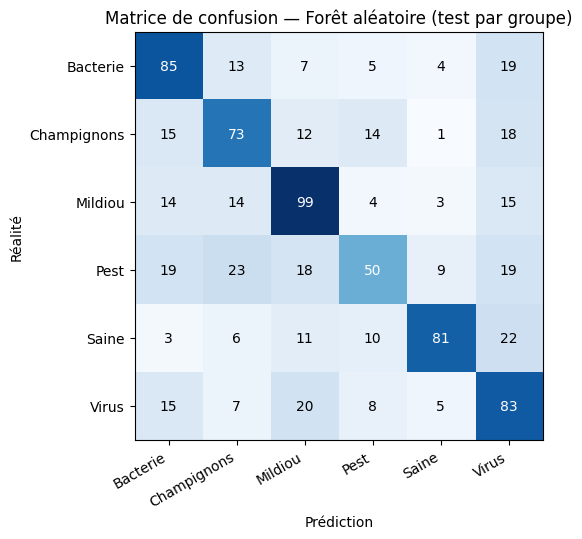

,images,rappel,précision,F1
Bacterie,133,0.639,0.563,0.599
Champignons,133,0.549,0.537,0.543
Mildiou,149,0.664,0.593,0.627
Pest,138,0.362,0.549,0.437
Saine,133,0.609,0.786,0.686
Virus,138,0.601,0.472,0.529


In [27]:
labels = meilleur.stages[0].labels
p = pred.select("classe", "prediction").toPandas()
p["prediction"] = p["prediction"].astype(int).map(lambda i: labels[i] if i < len(labels) else "?")
matrice = pd.crosstab(p["classe"], p["prediction"]).reindex(index=sorted(labels), columns=sorted(labels), fill_value=0)

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(matrice.values, cmap="Blues")
ax.set_xticks(range(len(matrice.columns))); ax.set_xticklabels(matrice.columns, rotation=30, ha="right")
ax.set_yticks(range(len(matrice.index))); ax.set_yticklabels(matrice.index)
for i in range(matrice.shape[0]):
    for j in range(matrice.shape[1]):
        ax.text(j, i, matrice.values[i, j], ha="center", va="center",
                color="white" if matrice.values[i, j] > matrice.values.max() / 2 else "black")
ax.set_xlabel("Prédiction"); ax.set_ylabel("Réalité")
ax.set_title(f"Matrice de confusion — {meilleur_nom} (test par groupe)")
plt.tight_layout(); plt.show()

par_classe = pd.DataFrame({
    "images": matrice.sum(axis=1),
    "rappel": np.diag(matrice) / matrice.sum(axis=1).replace(0, np.nan),
    "précision": np.diag(matrice) / matrice.sum(axis=0).replace(0, np.nan)})
par_classe["F1"] = 2 * par_classe["rappel"] * par_classe["précision"] / (par_classe["rappel"] + par_classe["précision"])
par_classe.round(3)

**Lecture des résultats par classe et de la matrice de confusion** (forêt aléatoire, 824 images de test,
entre 133 et 149 par classe).

**Vue d'ensemble.** La diagonale domine sur chaque ligne, pour chaque maladie, la prédiction la plus
fréquente est la bonne. Mais les erreurs sont **dispersées** sur plusieurs classes au lieu d'être concentrées
sur une paire de maladies proches. Cela confirme la limite des caractéristiques globales, elles donnent une
tendance, pas une signature nette de chaque maladie.

**1. Les feuilles saines sont rarement confondues avec des malades.**
- **Précision « Saine » = 0,786**, la meilleure de toutes. Quand le modèle dit « saine », il a raison
  presque 8 fois sur 10.
- Seules **22 feuilles malades sur 691 (3 %)** sont déclarées saines (colonne « Saine » hors diagonale :
  4 + 1 + 3 + 9 + 5). Pour un outil d'aide au diagnostic, c'est l'erreur la plus grave, car une maladie
  non détectée se propage dans la parcelle. Elle est rare ici.
- L'erreur inverse est plus fréquente : 52 feuilles saines sur 133 sont signalées malades (rappel de 0,609),
  surtout en « Virus » (22). Elle est moins grave, elle entraîne une vérification inutile, pas une maladie
  manquée.

**2. Le mildiou est la maladie la mieux reconnue** (rappel 0,664, F1 0,627). Ses grandes plages brunes de
tissu mort (nécroses) sont précisément ce que mesurent les caractéristiques `part_brun` et `part_sombre`.

**3. « Pest » (ravageurs) est la classe la plus difficile : rappel de 0,362.** Près des deux tiers des
images sont mal classées, et leurs erreurs se répartissent sur **toutes** les autres classes (19, 23, 18, 9,
19). Les dégâts d'insectes sont des **trous, des morsures sur les bords et des insectes visibles**. Ce sont
des formes, pas des couleurs. Des statistiques globales de couleur ne les voient pas. Quand le modèle prédit
« Pest », il a raison un peu plus d'une fois sur deux (précision 0,549), le problème est qu'il ne la prédit
pas assez souvent.

**4. « Virus » sert de classe « fourre-tout » : précision de 0,472.** C'est la classe la plus prédite
(176 fois pour 138 images réelles), et plus de la moitié de ces prédictions sont fausses. Les symptômes
viraux (mosaïque de vert clair et foncé, jaunissement, feuilles enroulées) sont **diffus et variables**.
Une image ambiguë, avec un peu de jaune et une texture irrégulière, finit donc souvent en « Virus », y
compris des feuilles saines (22) et des feuilles attaquées par des ravageurs (19).

**5. Bactérie et champignons se confondent entre eux** (13 et 15 erreurs dans chaque sens). Les deux
produisent des **taches brunes sur la feuille**, ce qui les distingue (taches anguleuses et humides pour les
bactéries, taches rondes à anneaux concentriques pour les champignons) est une question de **forme**, que nos
caractéristiques ne décrivent pas.

**Conclusion.** Les classes qui reposent sur la **couleur** (mildiou, feuille saine) sont bien reconnues.
Celles qui reposent sur la **forme** (ravageurs, différence bactérie/champignon) le sont mal. 
### 6.3 Mesure de la fuite de données : découpage fourni (A) contre découpage par groupe (B)
On entraîne le même meilleur modèle (mêmes hyperparamètres) sur le découpage fourni, et on compare.

In [28]:
modele_A = Pipeline(stages=[indexeur, normaliseur, meme_modele(meilleur_nom, meilleur)]).fit(train_A)
comparaison = pd.DataFrame({
    "A : découpage fourni (avec fuite)": scores(modele_A.transform(test_A)),
    "B : découpage par groupe (sans fuite)": scores(pred)}).T
comparaison.round(3)

,accuracy,weightedFMeasure,weightedPrecision,weightedRecall
A : découpage fourni (avec fuite),0.589,0.582,0.607,0.589
B : découpage par groupe (sans fuite),0.572,0.570,0.583,0.572


In [29]:
ecart = comparaison.iloc[0]["accuracy"] - comparaison.iloc[1]["accuracy"]
print(f"Écart d'accuracy (A - B) : {ecart:+.3f}")
print("Photos d'origine dans le test : A =", test_A.select("groupe").distinct().count(),
      "| B =", test_B.select("groupe").distinct().count())
if ecart > 0.03:
    print("Le découpage fourni surestime la performance : une partie de son score vient de photos déjà vues à l'entraînement.")
elif ecart < -0.03:
    print("Le découpage fourni donne un score plus faible : les deux tests ne contiennent pas les mêmes photos,"
          " et avec peu de photos de test la comparaison est très bruitée. La fuite n'a pas gonflé le score ici.")
else:
    print("L'écart est faible : la fuite existe, mais elle gonfle peu le score de ce modèle.")

Écart d'accuracy (A - B) : +0.017
Photos d'origine dans le test : A = 464 | B = 577
L'écart est faible : la fuite existe, mais elle gonfle peu le score de ce modèle.


**Lecture de la comparaison A / B.**

| Découpage | Accuracy | F1 pondéré | Photos d'origine dans le test |
|---|---|---|---|
| A : fourni (avec fuite) | 0,589 | 0,582 | 464 |
| B : par groupe (sans fuite) | 0,572 | 0,570 | 577 |

**Résultat : la fuite ne gonfle le score que de 1,7 point**, alors que 51 % des images du test A ont une
version dans l'entraînement (section 3.2). Cet écart n'est même **pas significatif**, avec 479 images de
test, la marge d'erreur d'une accuracy de 0,58 est d'environ ±4,4 points (intervalle de confiance à 95 %,
1,96 × √(0,58 × 0,42 / 479)). De plus, A et B n'ont ni le même test, ni exactement le même entraînement.

**Pourquoi la fuite rapporte-t-elle si peu ?** Une fuite n'avantage que les modèles capables de
**mémoriser** des exemples précis. Notre forêt aléatoire (profondeur 10) travaille sur 31 statistiques
globales, et chacune de ses feuilles regroupe de nombreuses images. Elle apprend des **tendances** (« plutôt
brun donc plutôt mildiou »), pas des images individuelles. Reconnaître qu'une image du test est la version
tournée d'une image vue à l'entraînement ne l'aide donc pas beaucoup, elle classe cette image avec la même
règle générale que les autres, et les erreurs du modèle viennent des **limites des caractéristiques**, pas
d'un manque de données.

**Pourquoi la correction reste indispensable.** Le résultat dépend du **modèle**, pas des données :
- un modèle à forte capacité de mémorisation, comme un **réseau de neurones convolutif** ou un **k plus proches voisins**, reconnaîtrait directement les photos déjà vues.
  Avec 51 % du test contaminé, il pourrait gagner jusqu'à des dizaines de points sur le test A, sans être
  meilleur sur de nouvelles photos.
- un score mesuré sur un test contaminé n'est **jamais** une mesure fiable, même quand il ressemble au bon
  score, on ne peut pas savoir à l'avance de combien il est gonflé.

**Conclusion.** Le score retenu est celui du découpage B : **57,2 % d'accuracy, F1 de
0,570**. La règle reste la même : **découper d'abord, augmenter ensuite**, et seulement sur l'entraînement.

### 6.4 Importance des caractéristiques
Pour la forêt aléatoire, MLlib fournit `featureImportances` : la part de la réduction d'impureté (qualité des
séparations dans les arbres) due à chaque caractéristique.

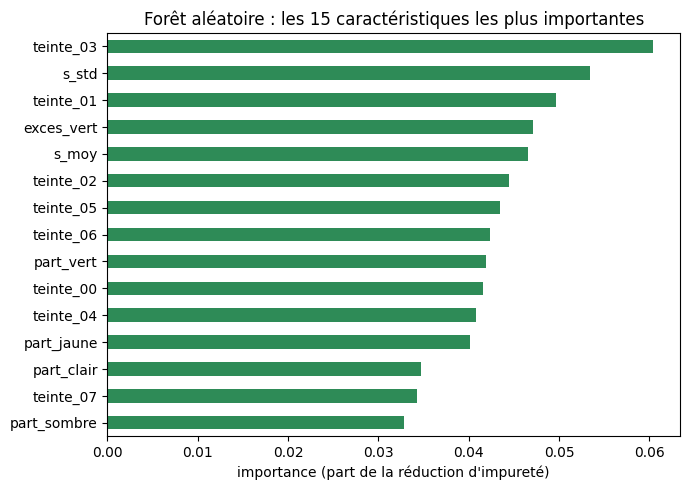

teinte_03     0.060
s_std         0.053
teinte_01     0.050
exces_vert    0.047
s_moy         0.047
teinte_02     0.045
teinte_05     0.043
teinte_06     0.042
part_vert     0.042
teinte_00     0.042
dtype: float64

In [30]:
rf_modele = modeles_B["Forêt aléatoire"].stages[-1]
importances = pd.Series(rf_modele.featureImportances.toArray(), index=NOMS).sort_values()
ax = importances.tail(15).plot(kind="barh", figsize=(7, 5), color="seagreen")
ax.set_title("Forêt aléatoire : les 15 caractéristiques les plus importantes")
ax.set_xlabel("importance (part de la réduction d'impureté)")
plt.tight_layout(); plt.show()
importances.iloc[::-1].head(10).round(3)

**Lecture des importances** 

Pour lire les teintes, l'histogramme découpe le cercle des couleurs en 12 tranches de 30°.

| Caractéristique | Teinte | Couleur | Ce qu'elle capte sur une feuille |
|---|---|---|---|
| `teinte_00` | 0–30° | rouge, brun-rouge | nécroses foncées |
| `teinte_01` | 30–60° | orange, brun, jaune-orangé | **tissus morts, taches brunes** |
| `teinte_02` | 60–90° | jaune, jaune-vert | **jaunissement (chlorose)**, mosaïque virale |
| `teinte_03` | 90–120° | **vert franc** | **tissu sain** |
| `teinte_04` | 120–150° | vert | tissu sain |
| `teinte_05`, `teinte_06` | 150–210° | vert-bleu, cyan | peu présent sur une feuille : **fond, éclairage** |

**1. Le modèle lit la maladie comme un déplacement de la couleur, du vert vers le brun.** Les caractéristiques
en tête correspondent exactement aux étapes visibles d'une maladie :
- `teinte_03` (vert franc, 1ʳᵉ) et `exces_vert` (4ᵉ) mesurent combien de tissu est encore sain 
- `teinte_02` (jaune-vert) et `part_jaune` mesurent le jaunissement 
- `teinte_01` (brun-orangé, 3ᵉ) et `teinte_00` mesurent les tissus morts.
C'est cohérent avec ce qu'un agronome regarde en premier, et ça rassure sur la pertinence du modèle.

**2. La saturation est très utile, surtout sa variabilité** (`s_std`, 2ᵉ ; `s_moy`, 5ᵉ). Une feuille saine a
une couleur **homogène**. Une feuille malade alterne zones vives et zones ternes (taches, mosaïque, bords
desséchés), ce qui augmente l'écart-type de la saturation. `s_std` mesure donc l'**hétérogénéité** de la
feuille, un symptôme commun à presque toutes les maladies.

**3. Point de vigilance : `teinte_05` et `teinte_06` (vert-bleu, cyan) sont 7ᵉ et 8ᵉ.** Ces couleurs sont
rares sur une feuille de pomme de terre. Elles viennent probablement du **fond de la photo** ou de
l'**éclairage** (ciel, ombre bleutée, balance des blancs de l'appareil). Si les photos d'une classe ont été
prises dans des conditions particulières (même champ, même jour, même téléphone), le modèle peut reconnaître
ces conditions plutôt que la maladie. C'est un **biais de contexte** classique en vision par ordinateur. Pour
le vérifier, il faudrait isoler la feuille du fond avant de calculer les caractéristiques.

**4. Aucune caractéristique ne domine.** La plus importante ne pèse que 6 %, alors qu'une répartition
uniforme entre les 31 caractéristiques donnerait 3,2 % chacune. Le modèle combine de nombreux indices
faibles, et aucune caractéristique ne suffit à elle seule. C'est cohérent avec les erreurs dispersées de la
matrice de confusion (6.2).

**5. Les caractéristiques de texture sont absentes du top 15** (`gradient_moy`, `gradient_std`,
`laplacien_var`). Elles résument la netteté de toute l'image, ce qui dépend autant de la mise au point de
l'appareil et du fond que de la feuille. Elles ne captent donc pas les formes qui distinguent les ravageurs
et les bactéries des champignons. Cela confirme la conclusion de la section 6.2.

**Limites de cette mesure.**
- **Caractéristiques corrélées.** Quand deux caractéristiques portent la même information, la forêt utilise
  tantôt l'une, tantôt l'autre, et leur importance est **partagée** entre elles. C'est pourquoi `part_brun`
  n'apparaît pas dans le top 15, alors que les taches brunes sont un symptôme majeur.
- **L'importance par impureté favorise les variables continues** à nombreuses valeurs, et elle est calculée
  sur l'entraînement.
- **Importance n'est pas causalité** : une caractéristique importante est utile à la prédiction, mais elle
  ne prouve pas que le modèle regarde la maladie.
### 6.5 Synthèse de l'évaluation
La cellule suivante résume les résultats de cette exécution.

In [31]:
print(f"Images : {donnees.count()} | photos d'origine : {donnees.select('groupe').distinct().count()}")
print(f"Meilleur modèle : {meilleur_nom}")
print(f"Test par groupe (B) : accuracy {comparaison.iloc[1]['accuracy']:.3f}, F1 pondéré {comparaison.iloc[1]['weightedFMeasure']:.3f}")
print(f"Test fourni (A)     : accuracy {comparaison.iloc[0]['accuracy']:.3f} (écart A - B : {ecart:+.3f})")
print(f"Référence (classe majoritaire) : accuracy {acc_reference:.3f}")
f1_classes = par_classe["F1"].dropna()
print("Classes les mieux reconnues  :", f1_classes.nlargest(2).round(2).to_dict())
print("Classes les moins reconnues  :", f1_classes.nsmallest(2).round(2).to_dict())

Images : 4318 | photos d'origine : 3052
Meilleur modèle : Forêt aléatoire
Test par groupe (B) : accuracy 0.572, F1 pondéré 0.570
Test fourni (A)     : accuracy 0.589 (écart A - B : +0.017)
Référence (classe majoritaire) : accuracy 0.161
Classes les mieux reconnues  : {'Saine': 0.69, 'Mildiou': 0.63}
Classes les moins reconnues  : {'Pest': 0.44, 'Virus': 0.53}


## 7. Déploiement



### 7.1 Modèle final
On réentraîne le meilleur pipeline (mêmes hyperparamètres) sur **toutes** les images (découpage B : train et
test), pour profiter de toutes les photos disponibles.

In [32]:
tout = ajouter_poids(donnees)
modele_final = Pipeline(stages=[indexeur, normaliseur, meme_modele(meilleur_nom, meilleur)]).fit(tout)
print("Modèle final :", meilleur_nom, "entraîné sur", tout.count(), "images")

Modèle final : Forêt aléatoire entraîné sur 4318 images


### 7.2 Sauvegarde du modèle Spark
`PipelineModel.save` enregistre tout le pipeline (indexeur, normalisation, modèle) dans un dossier, au format
MLlib, rechargeable avec `PipelineModel.load`, y compris sur un cluster.



In [33]:
from pyspark.ml import PipelineModel
DOSSIER_MODELE = os.path.abspath("modele_pommes_de_terre_spark")
try:
    modele_final.write().overwrite().save(uri(DOSSIER_MODELE))
    recharge = PipelineModel.load(uri(DOSSIER_MODELE))
    a = modele_final.transform(test_B).select("prediction").toPandas()
    b = recharge.transform(test_B).select("prediction").toPandas()
    print("Modèle Spark sauvegardé dans", DOSSIER_MODELE)
    print("Prédictions identiques après rechargement :", a.equals(b))
    SAUVEGARDE_SPARK = True
except Exception as e:
    SAUVEGARDE_SPARK = False
    print("Sauvegarde Spark impossible dans cet environnement (winutils absent sous Windows) :")
    print("   ", str(e).splitlines()[0][:200])

Sauvegarde Spark impossible dans cet environnement (winutils absent sous Windows) :
    An error occurred while calling o17316.save.


**Résultat.** La sauvegarde Spark échoue. Sous Windows, Spark a besoin de `winutils.exe` pour
écrire sur le disque local, et cet outil n'est pas fourni par `pip install pyspark`. Le modèle reste
utilisable **dans cette session**, mais il ne peut pas
être rechargé plus tard. Sur un cluster Linux, cette même ligne de code fonctionnerait sans modification, en
écrivant directement dans HDFS (`hdfs://namenode:9000/modeles/pommes_de_terre`). On passe donc à un format
d'export **indépendant de Spark**.

### 7.3 Export portable de la régression logistique
Une régression logistique se résume à quelques tableaux de nombres : les moyennes et écarts-types de la
normalisation, une matrice de coefficients (une ligne par classe) et un vecteur d'ordonnées à l'origine. On
peut les exporter en **JSON** (lisible, indépendant de Spark et de sa version) et refaire la prédiction avec
**NumPy** : `scores = coefficients × ((x − moyenne) / écart-type) + ordonnées`, puis *softmax*.

On exporte la régression logistique entraînée sur toutes les images, **quel que soit le meilleur modèle**
(une forêt aléatoire n'est pas exportable aussi simplement). 

In [34]:
import json

lr_final = Pipeline(stages=[indexeur, normaliseur,
                            meme_modele("Régression logistique", modeles_B["Régression logistique"])]).fit(tout)
idx_m, norm_m, lr_m = lr_final.stages

export = {
    "classes": idx_m.labels,
    "caracteristiques": NOMS,
    "moyenne": norm_m.mean.toArray().tolist(),
    "ecart_type": norm_m.std.toArray().tolist(),
    "coefficients": lr_m.coefficientMatrix.toArray().tolist(),
    "ordonnees": lr_m.interceptVector.toArray().tolist(),
    "metadonnees": {"modele": "Régression logistique multinomiale (Spark MLlib)",
                    "regParam": lr_m.getRegParam(), "spark": spark.version,
                    "images": tout.count(), "date": time.strftime("%Y-%m-%d %H:%M"),
                    "score_test_par_groupe": {k: round(v, 3) for k, v in scores(predictions_B["Régression logistique"]).items()}},
}
with open("modele_pommes_de_terre.json", "w", encoding="utf-8") as fichier_json:
    json.dump(export, fichier_json, ensure_ascii=False, indent=1)
print("Export :", os.path.abspath("modele_pommes_de_terre.json"), f"({os.path.getsize('modele_pommes_de_terre.json') / 1024:.1f} Ko)")

Export : c:\Users\Brahimi\Desktop\2026_2027\Fondements\modele_pommes_de_terre.json (8.1 Ko)


In [35]:
# rechargement et vérification : NumPy doit reproduire exactement les prédictions de Spark
with open("modele_pommes_de_terre.json", encoding="utf-8") as fichier_json:
    M = json.load(fichier_json)
moy, et = np.array(M["moyenne"]), np.array(M["ecart_type"])
W, b0 = np.array(M["coefficients"]), np.array(M["ordonnees"])

def probabilites(X):
    Z = ((X - moy) / np.where(et == 0, 1, et)) @ W.T + b0
    Z = np.exp(Z - Z.max(axis=1, keepdims=True))
    return Z / Z.sum(axis=1, keepdims=True)

verif = lr_final.transform(test_B).select("features_brutes", "probability").toPandas()
P_spark = np.vstack(verif["probability"].map(lambda v: v.toArray()))
P_numpy = probabilites(np.vstack(verif["features_brutes"].map(lambda v: v.toArray())))
print(f"{len(verif)} images : écart maximal de probabilité Spark / NumPy = {np.abs(P_spark - P_numpy).max():.2e}")
print("Mêmes classes prédites :", (P_spark.argmax(1) == P_numpy.argmax(1)).all())

824 images : écart maximal de probabilité Spark / NumPy = 5.00e-16
Mêmes classes prédites : True


**Lecture.** Sur les 824 images du test B, les probabilités calculées avec NumPy à partir du fichier JSON
(8,1 Ko) ne diffèrent de celles de Spark que de **5 × 10⁻¹⁶**, c'est-à-dire de l'arrondi du calcul en
virgule flottante. Les classes prédites sont **toutes identiques**. Le fichier JSON contient donc bien
**tout** le modèle, et il peut tourner sans Spark ni Java, sur n'importe quelle machine avec NumPy.

### 7.3 (modification) : Export portable de la forêt aléatoire
La régression logistique exportée en JSON est portable, mais elle est moins bonne que la forêt aléatoire
(F1 de 0,453 contre 0,570 sur le test B). On veut déployer le **meilleur** modèle. On réentraîne donc une
forêt aléatoire avec **scikit-learn**, sur exactement les mêmes caractéristiques, les mêmes poids de classes
et les mêmes hyperparamètres que ceux choisis par la validation croisée de Spark. On l'enregistre ensuite avec
`joblib`.

Les deux implémentations ne sont pas identiques au bit près. Spark découpe les variables continues en
32 intervalles (`maxBins`), alors que scikit-learn teste tous les seuils, et le tirage aléatoire diffère. On
vérifie donc, **sur le test B**, que la forêt scikit-learn obtient un score équivalent avant de l'adopter.

In [36]:
from sklearn.ensemble import RandomForestClassifier as ForetSklearn
import joblib

def vers_numpy(df):
    colonnes = ["features_brutes", "classe"] + (["poids"] if "poids" in df.columns else [])
    p = df.select(*colonnes).toPandas()
    X = np.vstack(p["features_brutes"].map(lambda v: v.toArray()))
    return X, p["classe"].values, (p["poids"].values if "poids" in p else None)

foret_spark = modeles_B["Forêt aléatoire"].stages[-1]
hyper = dict(n_estimators=foret_spark.getOrDefault("numTrees"), max_depth=foret_spark.getOrDefault("maxDepth"),
             max_features="sqrt", random_state=42, n_jobs=-1)
print("Hyperparamètres repris de Spark :", hyper)

# 1) Vérification : même entraînement (train B), même test (test B) que la forêt Spark
X_tr, y_tr, w_tr = vers_numpy(train_B)
X_te, y_te, _ = vers_numpy(test_B)
foret_verif = ForetSklearn(**hyper).fit(X_tr, y_tr, sample_weight=w_tr)
acc_sk = (foret_verif.predict(X_te) == y_te).mean()
print(f"Test B : forêt scikit-learn {acc_sk:.3f} | forêt Spark {tableau_B.loc['Forêt aléatoire', 'accuracy']:.3f}")

# 2) Modèle final : toutes les images, puis export
X_all, y_all, w_all = vers_numpy(tout)
foret_finale = ForetSklearn(**hyper).fit(X_all, y_all, sample_weight=w_all)
paquet = {"modele": foret_finale, "caracteristiques": NOMS, "classes": list(foret_finale.classes_),
          "metadonnees": {"modele": "Forêt aléatoire (scikit-learn, hyperparamètres choisis avec Spark MLlib)",
                          **{k: v for k, v in hyper.items() if k != "n_jobs"},
                          "images": len(y_all), "date": time.strftime("%Y-%m-%d %H:%M"),
                          "accuracy_test_par_groupe": round(float(acc_sk), 3)}}
joblib.dump(paquet, "modele_pommes_de_terre_foret.joblib")
print("Export :", os.path.abspath("modele_pommes_de_terre_foret.joblib"),
      f"({os.path.getsize('modele_pommes_de_terre_foret.joblib') / 1e6:.1f} Mo)")

Hyperparamètres repris de Spark : {'n_estimators': 150, 'max_depth': 10, 'max_features': 'sqrt', 'random_state': 42, 'n_jobs': -1}
Test B : forêt scikit-learn 0.575 | forêt Spark 0.572
Export : c:\Users\Brahimi\Desktop\2026_2027\Fondements\modele_pommes_de_terre_foret.joblib (12.9 Mo)


**Lecture.** Avec les hyperparamètres choisis par la validation croisée de Spark (150 arbres, profondeur 10),
la forêt scikit-learn obtient **0,575** d'accuracy sur le test B, contre **0,572** pour la forêt Spark. Les
deux sont **équivalentes**. L'écart de 0,3 point vient des différences d'implémentation (découpage des
variables en 32 intervalles chez Spark, tirage aléatoire des arbres), et il est bien plus petit que la marge
d'erreur du test (environ ±3,4 points avec 824 images). On peut donc déployer la forêt scikit-learn à la
place de la forêt Spark.

**Comparaison des deux exports.**

| | JSON (régression logistique) | joblib (forêt aléatoire) |
|---|---|---|
| Accuracy sur le test B | 0,460 | **0,575** |
| Taille | 8,1 Ko | 12,9 Mo |
| Dépendances | NumPy seul | scikit-learn (même version conseillée) |
| Lisible / auditable | oui (coefficients interprétables) | non (150 arbres) |

C'est un **compromis**. Le JSON est minuscule, transparent et utilisable partout, 
la forêt est 1 600 fois plus lourde, mais elle classe correctement 11 points d'images de plus. On retient la
**forêt** pour la fonction de prédiction. Le JSON reste une solution de secours, par exemple sur un appareil
très limité.

**Rôle de Spark dans cette chaîne.** Spark a fait le travail lourd et distribué : extraction des
caractéristiques de 4 318 images, validation croisée et choix des hyperparamètres. Une fois les
caractéristiques résumées en 31 nombres par image, le modèle final est assez petit pour être servi sans
cluster.



### 7.4 Fonction de prédiction pour une nouvelle photo
La fonction :
1. **vérifie** l'entrée : fichier existant, image lisible, taille minimale 
2. calcule les caractéristiques avec **la même fonction** qu'à l'entraînement (`caracteristiques`), pour
   éviter tout écart entre entraînement et production 
3. renvoie la classe prédite, les probabilités, et un **avertissement** si le modèle hésite (probabilité
   maximale faible) ou si l'image est très différente des images d'entraînement.

La fonction utilise la **forêt aléatoire** exportée en 7.3 (modification). Les moyennes et
écarts-types du fichier JSON servent seulement à repérer les images atypiques.

In [37]:
FORET = joblib.load("modele_pommes_de_terre_foret.joblib")      # modèle déployé : la forêt aléatoire
TAILLE_MIN = 64        # pixels : en dessous, les symptômes ne sont plus visibles
SEUIL_HESITATION = 0.5

def predire_image(chemin, modele=FORET):
    if not os.path.isfile(chemin):
        raise FileNotFoundError(f"Fichier introuvable : {chemin}")
    try:
        with Image.open(chemin) as im:
            im.verify()                                   # détecte les fichiers corrompus ou non images
        with Image.open(chemin) as im:
            largeur, hauteur = im.size
            mode = im.mode
    except Exception as e:
        raise ValueError(f"Image illisible ou corrompue : {chemin} ({type(e).__name__})")
    if min(largeur, hauteur) < TAILLE_MIN:
        raise ValueError(f"Image trop petite ({largeur}×{hauteur}) : au moins {TAILLE_MIN} pixels de côté")

    try:
        x = np.array(caracteristiques(chemin))[None, :]
    except Exception as e:                                # par exemple un JPEG tronqué, non détecté par verify()
        raise ValueError(f"Image illisible ou corrompue : {chemin} ({type(e).__name__}: {e})")
    proba = modele["modele"].predict_proba(x)[0]
    ordre = np.argsort(proba)[::-1]
    avertissements = []
    if mode not in ("RGB", "RGBA", "P"):
        avertissements.append(f"image en mode {mode} (pas en couleurs) : convertie, mais les couleurs sont absentes")
    if proba[ordre[0]] < SEUIL_HESITATION:
        avertissements.append(f"modèle hésitant : {modele['classes'][ordre[0]]} ({proba[ordre[0]]:.0%}) ou "
                              f"{modele['classes'][ordre[1]]} ({proba[ordre[1]]:.0%})")
    z = np.abs((x[0] - moy) / np.where(et == 0, 1, et))
    if (z > 6).any():
        hors = [NOMS[i] for i in np.where(z > 6)[0]]
        avertissements.append(f"image atypique (valeurs très éloignées de l'entraînement : {hors[:3]})")
    return {"classe": modele["classes"][ordre[0]], "probabilite": round(float(proba[ordre[0]]), 3),
            "top3": {modele["classes"][i]: round(float(proba[i]), 3) for i in ordre[:3]},
            "avertissements": avertissements}

### 7.5 Tests sur des cas normaux et des cas limites
On fabrique des fichiers de test à partir d'une image du jeu de test : une copie normale, une version PNG, une
version en niveaux de gris, une miniature, une image entièrement noire, un fichier tronqué (corrompu), un
fichier texte renommé en `.jpg`, et un chemin inexistant.

In [38]:
DOSSIER_TESTS = "tests_deploiement"
os.makedirs(DOSSIER_TESTS, exist_ok=True)
source = test_B.select("chemin").first()["chemin"] if test_B.count() else taches[0][0]
img = Image.open(source).convert("RGB")
cas = {}
cas["image normale (JPEG)"] = os.path.join(DOSSIER_TESTS, "normale.jpg"); img.save(cas["image normale (JPEG)"])
cas["même image en PNG"] = os.path.join(DOSSIER_TESTS, "image.png"); img.save(cas["même image en PNG"])
cas["niveaux de gris"] = os.path.join(DOSSIER_TESTS, "gris.jpg"); img.convert("L").save(cas["niveaux de gris"])
cas["image noire"] = os.path.join(DOSSIER_TESTS, "noire.jpg"); Image.new("RGB", (500, 500)).save(cas["image noire"])
cas["miniature 40×40"] = os.path.join(DOSSIER_TESTS, "mini.jpg"); img.resize((40, 40)).save(cas["miniature 40×40"])
octets = open(cas["image normale (JPEG)"], "rb").read()
cas["fichier tronqué"] = os.path.join(DOSSIER_TESTS, "tronque.jpg"); open(cas["fichier tronqué"], "wb").write(octets[:len(octets) // 3])
cas["texte renommé en .jpg"] = os.path.join(DOSSIER_TESTS, "faux.jpg"); open(cas["texte renommé en .jpg"], "w").write("pas une image")
cas["fichier inexistant"] = os.path.join(DOSSIER_TESTS, "absent.jpg")

resultats = []
for description, chemin in cas.items():
    try:
        r = predire_image(chemin)
        resultats.append({"cas": description, "résultat": f"{r['classe']} ({r['probabilite']:.0%})",
                          "avertissements": " | ".join(r["avertissements"]) or "—"})
    except Exception as e:
        resultats.append({"cas": description, "résultat": f"REFUSÉ — {type(e).__name__}", "avertissements": str(e)[:110]})
pd.set_option("display.max_colwidth", 130)
print("Classe réelle de l'image source :", test_B.select("classe").first()["classe"] if test_B.count() else "?")
pd.DataFrame(resultats)

Classe réelle de l'image source : Virus


,cas,résultat,avertissements
0,image normale (JPEG),Mildiou (45%),modèle hésitant : Mildiou (45%) ou Virus (34%)
1,même image en PNG,Mildiou (42%),modèle hésitant : Mildiou (42%) ou Virus (39%)
2,niveaux de gris,Virus (28%),"image en mode L (pas en couleurs) : convertie, mais les couleurs sont absentes | modèle hésitant : Virus (28%) ou Mildiou (23%)"
3,image noire,Virus (28%),modèle hésitant : Virus (28%) ou Mildiou (26%) | image atypique (valeurs très éloignées de l'entraînement : ['part_sombre'])
4,miniature 40×40,REFUSÉ — ValueError,Image trop petite (40×40) : au moins 64 pixels de côté
5,fichier tronqué,REFUSÉ — ValueError,Image illisible ou corrompue : tests_deploiement\tronque.jpg (OSError: image file is truncated (68 bytes not p
6,texte renommé en .jpg,REFUSÉ — ValueError,Image illisible ou corrompue : tests_deploiement\faux.jpg (UnidentifiedImageError)
7,fichier inexistant,REFUSÉ — FileNotFoundError,Fichier introuvable : tests_deploiement\absent.jpg


**Lecture des tests** (image source tirée du test B, classe réelle : **Virus**).

**Images valides : acceptées, avec un avertissement à chaque fois qu'il le faut.**

- **Image normale : Mildiou (45 %), alors que la vraie classe est Virus (34 %, en 2ᵉ position).** Le modèle
  se trompe, ce qui est cohérent avec ses 57 % d'accuracy. La matrice de confusion (6.2) montrait déjà 20
  feuilles virosées classées « Mildiou ». Surtout, la fonction **ne cache pas cette incertitude**. Aucune
  classe ne dépasse 50 %, l'avertissement « modèle hésitant » s'affiche, et la bonne réponse apparaît en
  2ᵉ position. Pour un outil d'aide au diagnostic, afficher les deux hypothèses est plus utile que de
  donner une seule réponse fausse avec assurance.

- **JPEG et PNG : même classe, mais probabilités légèrement différentes** (Mildiou 45 % / Virus 34 % contre
  42 % / 39 %). On s'attendait à des valeurs identiques. L'écart a deux causes :
  1. la version JPEG a été **recompressée** à l'enregistrement (compression avec perte), alors que le PNG
     garde les pixels exacts. Les deux fichiers ne contiennent donc pas tout à fait les mêmes pixels.
  2. la fonction `caracteristiques` utilise `im.draft()`, qui accélère le décodage **des JPEG seulement** en
     les décodant directement à taille réduite. Un PNG est réduit par un autre chemin, qui donne des pixels
     légèrement différents.

  C'est un petit **décalage entre entraînement et production**. Toutes les
  images d'entraînement étaient des JPEG. Il ne change pas la classe ici, mais une image dont les deux
  premières classes sont très proches pourrait basculer. En production, on convertirait toute image reçue
  en JPEG avec les mêmes réglages avant de calculer les caractéristiques, ou on supprimerait `draft()` pour
  traiter tous les formats de la même façon.

- **Niveaux de gris : Virus (28 %)**, et les probabilités sont presque uniformes (une sur six vaut 17 %).
  Sans couleur, le modèle n'a plus d'information, puisque ses caractéristiques les plus importantes sont
  des teintes (6.4). Deux avertissements s'affichent : image sans couleurs et modèle hésitant. La réponse
  « Virus » est un hasard et ne doit pas être utilisée.

- **Image noire : Virus (28 %).** Un modèle donne **toujours** une réponse, même absurde. Ici, la fonction
  signale que l'image est **atypique**. `part_sombre` (part de pixels sombres) est à plus de 6 écarts-types
  des images d'entraînement. Sans ce contrôle, on aurait annoncé « Virus » pour une image vide.

**Fichiers invalides : refusés avec un message explicite.**

| Cas | Contrôle qui le détecte |
|---|---|
| miniature 40×40 | taille minimale (64 pixels). Les symptômes ne seraient plus visibles |
| fichier tronqué | lecture de l'image (`OSError: image file is truncated`) |
| texte renommé en `.jpg` | `Image.verify()` : ce n'est pas une image (`UnidentifiedImageError`) |
| fichier inexistant | `FileNotFoundError` avant même d'ouvrir le fichier |

Le programme ne plante dans aucun cas, et chaque refus dit **pourquoi**. C'est ce qu'on attend d'une fonction
déployée. Elle reçoit des entrées qu'on ne contrôle pas.

**Bilan.** Les contrôles d'entrée fonctionnent. La limite principale du déploiement reste la **qualité du
modèle** (57 %), et les avertissements la rendent visible au lieu de la cacher.

### 7.6 Prédiction distribuée sur un lot d'images
Pour des milliers de nouvelles photos, on réutilise
Spark. Le même schéma `mapPartitions` calcule les caractéristiques en parallèle, puis le **pipeline Spark** du
modèle final prédit toutes les images d'un coup.

In [39]:
nouvelles = taches[:20]                                     # ici : 20 images, pour la démonstration
lot = (spark.createDataFrame(sc.parallelize(nouvelles, 4).mapPartitions(traiter_partition), schema)
            .filter(F.col("erreur").isNull())
            .withColumn("features_brutes", vers_vecteur("features_liste")))
resultat_lot = modele_final.transform(lot)
idx_labels = modele_final.stages[0].labels
vers_classe = F.udf(lambda i: idx_labels[int(i)] if int(i) < len(idx_labels) else "?", T.StringType())
(resultat_lot.withColumn("classe_predite", vers_classe("prediction"))
             .select(F.element_at(F.split("chemin", r"[/\\]"), -1).alias("fichier"), "classe", "classe_predite")
             .show(10, truncate=False))

+----------------------------------+-------+--------------+
|fichier                           |classe |classe_predite|
+----------------------------------+-------+--------------+
|20230712_132914_aug_13_aug_27.jpg |Virus  |Virus         |
|20230802_130014_aug_55_aug_111.jpg|Virus  |Mildiou       |
|20230802_120000_aug_40_aug_81.jpg |Virus  |Virus         |
|20230815_112519_aug_62_aug_125.jpg|Virus  |Virus         |
|20230802_105945_aug_19_aug_39.jpg |Mildiou|Mildiou       |
|20230802_120657_aug_44_aug_89.jpg |Virus  |Virus         |
|20230712_133012_aug_14_aug_29.jpg |Virus  |Virus         |
|20230802_120716_aug_48_aug_97.jpg |Virus  |Virus         |
|20230815_112609_aug_67_aug_135.jpg|Virus  |Virus         |
|20230802_120710_aug_47_aug_95.jpg |Virus  |Virus         |
+----------------------------------+-------+--------------+
only showing top 10 rows



**Lecture.** La chaîne de prédiction par lot fonctionne de bout en bout avec Spark : extraction parallèle
des caractéristiques (`mapPartitions`), conversion en vecteurs, puis prédiction par le pipeline complet
(indexation, normalisation, forêt aléatoire). Le même code traiterait des milliers d'images, ou les
photos d'un champ entier prises par un drone, sur un cluster.

**Attention à ne pas lire ces résultats comme un score.** On obtient 9 bonnes réponses sur les 10 images
affichées, bien plus que les 57 % mesurés en 6.1. Mais ces 20 images de démonstration font partie des
données d'entraînement, et le modèle final a été entraîné sur **toutes** les images (7.1). Il les a déjà
vues. Le seul score valable reste celui du **test par groupe (6.1)**. Sur de vraies nouvelles photos, il faut
s'attendre à environ 57 % de bonnes réponses, avec des erreurs du type « Virus » → « Mildiou » (ligne 2),
la confusion déjà repérée dans la matrice de la section 6.2.

**Les noms de fichiers confirment l'augmentation en cascade.** Des noms comme
`20230712_132914_aug_13_aug_27.jpg` portent **deux** suffixes `_aug_`. L'auteur du dataset a augmenté des
images qui étaient déjà augmentées. L'expression régulière de la section 3.1, `(_aug_\d+)+$`, retire tous
les suffixes à la suite (grâce au `+`). Ces images sont donc bien rattachées à leur photo d'origine
`20230712_132914`. Les noms donnent aussi les **dates de prise de vue** (12 juillet, 2 et 15 août 2023).

### 7.7 Limites et suivi
| Limite | Conséquence | Piste |
|---|---|---|
| Caractéristiques simples (couleur, texture) | les maladies aux symptômes proches se confondent | extraire des caractéristiques avec un réseau pré-entraîné (ResNet, EfficientNet), distribué avec Spark (`pandas_udf`) |
| Augmentation faite avant le découpage par l'auteur du dataset | scores du découpage fourni trop optimistes | découper par photo d'origine (fait ici), augmenter après le découpage |
| Photos d'une seule campagne (juillet-août 2023, d'après les noms de fichiers) | le modèle peut dépendre de la lumière, du terrain, de l'appareil | tester sur des photos d'autres champs et d'autres saisons |
| Lecture locale et non depuis HDFS (Windows + Docker) | pas de localité des données dans cette démonstration | exécuter Spark sur le cluster (YARN), qui lirait `hdfs://` directement |

## 8. Conclusion de la partie 2

**Données.** 4 318 images (2,9 Go) de feuilles de pomme de terre réparties en 6 classes presque équilibrées.

**Hadoop HDFS.** Les images ont été copiées dans HDFS en 699 s (environ 4 Mo/s). Ce débit très faible
illustre le **problème des petits fichiers**. HDFS est conçu pour de gros fichiers découpés en blocs de
128 Mo, et chaque image de quelques centaines de Ko coûte une entrée en mémoire du NameNode et un aller-retour
réseau. Dans un vrai système Big Data, on regrouperait les images dans de gros fichiers (Parquet,
SequenceFile).

**Spark** a traité toute la chaîne de façon distribuée :
- inventaire et empreintes des fichiers (`binaryFile`, `sha2`) 
- extraction parallèle de 31 caractéristiques par image (`mapPartitions`) 
- découpage par groupe (`hash`) 
- validation croisée de 23 modèles (**MLlib**) 
- prédiction par lot.

Deux leçons pratiques :
- le **nombre de partitions** doit suivre le coût du traitement par ligne. Passer de 107 à 4 partitions a fait
  descendre la validation croisée de plus de 11 minutes (inachevée) à 2 min 24 s 
- les données vivent dans la **JVM**. Un arrêt de Spark fait tout perdre, d'où l'intérêt des points de
  reprise (*checkpoints*).

**Qualité des données.** Une **fuite massive** a été découverte dans le découpage fourni. 51 % des images
du test ont une version, originale ou augmentée, dans l'entraînement, parce que les images ont été augmentées
**avant** d'être découpées. Un découpage **par photo d'origine** corrige ce problème. Avec notre modèle, la
fuite ne gonfle le score que de 1,7 point, un écart non significatif. Une forêt sur des statistiques
globales ne mémorise pas les images individuelles. Un réseau de neurones, lui, en aurait profité, et la
correction reste donc indispensable.

**Modèle.**
- La **forêt aléatoire** (150 arbres, profondeur 10) atteint **57,2 % d'accuracy (F1 0,570)** sur des photos
  jamais vues, contre 16,1 % pour la référence et 46,0 % pour la régression logistique.
- Les feuilles saines sont rarement confondues avec des malades. Seules 3 % des feuilles malades sont
  déclarées saines.
- Les maladies reconnaissables à leur **couleur** (mildiou) sont bien classées. Celles qui se reconnaissent
  à leur **forme** (ravageurs, bactérie contre champignon) le sont mal.

**Déploiement.**
- La sauvegarde au format Spark est impossible sous Windows (`winutils`).
- Le modèle est donc exporté dans deux formats portables, vérifiés :
  - un **JSON** de 8 Ko (régression logistique, reproduit par NumPy à 5 × 10⁻¹⁶ près).
  - un fichier **joblib** (forêt aléatoire, 0,575 sur le test B, équivalente à la forêt Spark).
- La fonction de prédiction refuse les fichiers invalides, signale les images atypiques et les prédictions
  hésitantes, et ne plante dans aucun des 8 cas testés.

**Perspective principale.** Remplacer les 31 caractéristiques faites à la main par celles d'un **réseau de
neurones pré-entraîné** (ResNet, EfficientNet), calculées en parallèle avec Spark (`pandas_udf`). Ce
réseau capterait les formes des symptômes, qui manquent aujourd'hui au modèle.

In [40]:
spark.stop()